# Notebook 03 - Manchester United Defensive Controller Recruitment Analysis

## Purpose
Present the results calculated in Notebook 02 as clear recruitment comparisons. **Do not recalculate the Controller Score or refit the market-value model.**

This notebook uses the three processed CSV exports from Notebook 02. Estimated market values are not transfer fees, and qualitative feasibility tiers are provisional scouting judgements.

## 1. Load processed recruitment datasets

Load the already-engineered eligible-player dataset, the recruitment pool and the ten-player shortlist. Verify the expected schemas and population sizes before plotting.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works when this notebook is run from the repository root or from notebooks/.
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [current, *current.parents] if (p / "data" / "processed").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/processed. Run Notebook 02 exports first.")

processed = PROJECT_ROOT / "data" / "processed"
eligible = pd.read_csv(processed / "defensive_controller_candidates_2025_26.csv")
pool = pd.read_csv(processed / "recruitment_pool_2025_26.csv")
shortlist = pd.read_csv(processed / "defensive_controller_shortlist_2025_26.csv")

print(f"Eligible players: {len(eligible)} | Recruitment pool: {len(pool)} | Shortlist: {len(shortlist)}")
required = {"player", "controller_score", "market_value_m", "feasibility_tier"}
missing = required - set(shortlist.columns)
if missing:
    raise ValueError(f"Shortlist missing required columns: {sorted(missing)}")
print("Shortlist columns:", shortlist.columns.tolist())
shortlist.head(10)

Eligible players: 248 | Recruitment pool: 95 | Shortlist: 10
Shortlist columns: ['player', 'age', 'season_teams', 'controller_score', 'market_value_m', 'value_residual', 'defensive_activity_score', 'possession_control_score', 'progression_score', 'ball_recovery_score', 'physical_duels_score', 'feasibility_tier']


,player,age,season_teams,controller_score,market_value_m,value_residual,defensive_activity_score,possession_control_score,progression_score,ball_recovery_score,physical_duels_score,feasibility_tier
0,Eduardo Camavinga,23.6,Real Madrid,82.479839,48.000000,26.553071,77.688172,90.322581,88.709677,62.096774,95.362903,Very Difficult
1,Aurélien Tchouaméni,26.4,Real Madrid,81.182796,73.000000,22.852368,82.930108,93.682796,72.379032,62.903226,89.717742,Very Difficult
2,Mamadou Sangare,24.0,RC Lens,77.143817,39.000000,22.400328,75.268817,59.139785,79.838710,99.596774,88.709677,Very Difficult
3,Pedri,23.6,FC Barcelona,76.538978,164.000000,13.533057,45.295699,79.301075,97.177419,98.790323,88.709677,Very Difficult
4,Éderson,27.0,Atalanta,73.602151,43.000000,18.302940,66.801075,77.150538,77.419355,80.645161,66.935484,Difficult
5,Jobe Bellingham,20.8,Borussia Dortmund,72.614247,38.000000,18.018378,80.040323,67.069892,59.072581,86.290323,70.766129,Difficult
6,Vitinha,26.4,Paris Saint-Germain,72.116935,130.000000,10.456429,39.112903,89.919355,99.395161,89.919355,45.362903,Very Difficult
7,Tom Krauß,25.0,1. FC Köln,70.866935,4.700000,27.483985,89.247312,56.854839,34.879032,94.758065,86.895161,Potential Opportunity
8,Pepelu,27.9,Valencia,70.564516,7.300000,24.990465,65.591398,65.725806,74.193548,87.500000,64.919355,Potential Opportunity
9,Cristian Cásseres Jr.,26.4,Toulouse,70.322581,8.199999,24.148276,76.478495,46.774194,68.145161,97.580645,74.193548,Potential Opportunity



### Findings: Recruitment Dataset Overview

All three processed datasets were successfully loaded from Notebook 02.

The recruitment pipeline produced:

- **248 eligible midfielders** meeting the minimum 1,500-minute threshold.
- **95 recruitment candidates** after applying the age and Premier League exclusion criteria.
- **10 shortlisted players** ranked in the top 10% of the recruitment pool by Defensive Controller Score.

The shortlist includes performance scores across five tactical dimensions, estimated market values, value residuals and preliminary transfer-feasibility classifications.

**Initial observations:**

- Eduardo Camavinga leads the shortlist with a Controller Score of 82.48, followed by Aurélien Tchouaméni at 81.18.
- Mamadou Sangare ranks third with a score of 77.14, supported by a particularly strong Ball Recovery Score of 99.60.
- Tom Krauß, Pepelu and Cristian Cásseres Jr. are the lowest-valued shortlisted candidates, with estimated market values below €10 million.
- These three players also have the largest positive value residuals among the shortlisted candidates, suggesting strong modelled performance relative to their estimated valuations.

**Important distinction:** The Controller Score measures performance suitability for the defined role, while the value residual measures performance relative to a simple market-value regression. Neither directly establishes transfer availability or affordability.

The following sections visualise the shortlist and compare player profiles to support the final recruitment recommendations.


## 2. Performance shortlist ranking

Show the ten shortlisted midfielders ordered by the existing Controller Score. This is **role-fit ranking**, not a ranking of transfer feasibility.

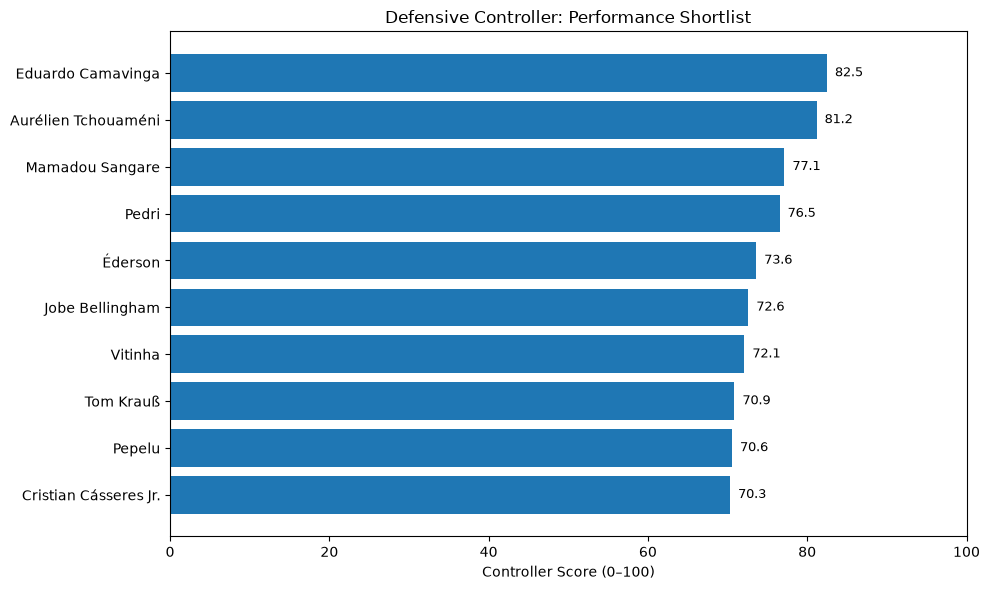

In [6]:
ranked = shortlist.sort_values("controller_score", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(ranked["player"], ranked["controller_score"])
ax.set(xlabel="Controller Score (0–100)", title="Defensive Controller: Performance Shortlist")
ax.set_xlim(0, 100)
for bar, score in zip(bars, ranked["controller_score"]):
    ax.text(score + 1, bar.get_y() + bar.get_height()/2, f"{score:.1f}", va="center", fontsize=9)
fig.tight_layout()
plt.savefig(
    PROJECT_ROOT / "assets" / "controller_rankings.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Findings: Defensive Controller Performance Rankings

The chart ranks the ten shortlisted midfielders using the weighted Defensive Controller Score developed in Notebook 02.

**Key findings:**

- **Eduardo Camavinga (82.5)** ranks first, narrowly ahead of **Aurélien Tchouaméni (81.2)**. Both demonstrate strong overall alignment with the defined Defensive Controller profile.
- **Mamadou Sangare (77.1)** ranks third, ahead of Pedri (76.5), highlighting his strong overall performance across the selected role-specific metrics.
- **Éderson (73.6), Jobe Bellingham (72.6) and Vitinha (72.1)** form the middle of the performance shortlist.
- **Tom Krauß (70.9), Pepelu (70.6) and Cristian Cásseres Jr. (70.3)** occupy the final three positions, but all remain within the top 10% of the recruitment pool.

**Recruitment interpretation:**

The highest-scoring players are not necessarily the most practical transfer targets.

Camavinga and Tchouaméni lead the performance rankings, but their preliminary recruitment-feasibility classifications indicate substantial acquisition challenges.

Meanwhile, Krauß, Pepelu and Cásseres Jr. combine competitive Controller Scores with considerably lower estimated market values.

**Conclusion:** The Controller Score provides an initial performance-based ranking, but final recruitment recommendations must also consider tactical strengths, estimated market value and transfer feasibility.

The next stage examines the five tactical dimensions underlying these overall scores to understand how individual player profiles differ.


## 3. Compare tactical dimensions

Display the five component scores for the highest-ranked five players. The heatmap highlights different routes to a strong overall score without treating the dimensions as identical.

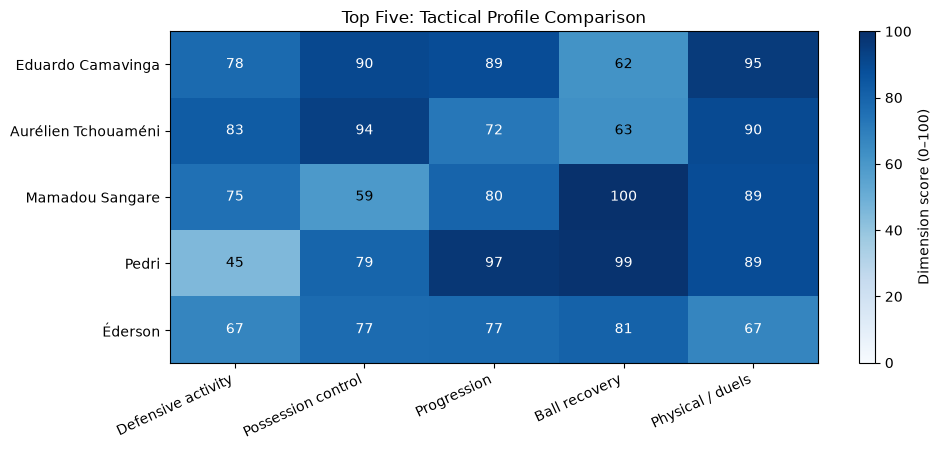

In [7]:
dimensions = {
    "defensive_activity_score": "Defensive activity",
    "possession_control_score": "Possession control",
    "progression_score": "Progression",
    "ball_recovery_score": "Ball recovery",
    "physical_duels_score": "Physical / duels",
}
top_five = shortlist.nlargest(5, "controller_score").set_index("player")
missing = set(dimensions) - set(top_five.columns)
if missing:
    raise ValueError(f"Missing component scores: {sorted(missing)}")
values = top_five[list(dimensions)].to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(values, vmin=0, vmax=100, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(dimensions)), list(dimensions.values()), rotation=25, ha="right")
ax.set_yticks(range(len(top_five)), top_five.index)
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(j, i, f"{values[i,j]:.0f}", ha="center", va="center", color="white" if values[i,j] > 65 else "black")
fig.colorbar(im, ax=ax, label="Dimension score (0–100)")
ax.set_title("Top Five: Tactical Profile Comparison")
fig.tight_layout()
plt.savefig(
    PROJECT_ROOT / "assets" / "tactical_profiles.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Findings: Tactical Profile Comparison

The heatmap compares the five highest-ranked midfielders across the five weighted dimensions of the Defensive Controller model.

**Key findings:**

- **Eduardo Camavinga:** Demonstrates a well-rounded profile, particularly in Possession Control (90), Progression (89) and Physical/Duels (95). His Ball Recovery Score (62) is comparatively weaker, suggesting that his strengths within this model lie more in possession management, progression and duelling.

- **Aurélien Tchouaméni:** Records the highest Possession Control Score (94) among the five players, alongside strong Defensive Activity (83) and Physical/Duels (90). His profile closely matches the requirements of a midfielder who can combine defensive responsibility with reliable possession management.

- **Mamadou Sangare:** Stands out for Ball Recovery (100), Physical/Duels (89) and Progression (80). However, his Possession Control Score (59) is substantially lower than those of Camavinga and Tchouaméni. This suggests a stronger ball-winning profile than a possession-dominant controller profile.

- **Pedri:** Excels in Progression (97) and Ball Recovery (99), but has the lowest Defensive Activity Score (45) among the five. His profile suggests a different tactical emphasis from that of a traditional defensive midfielder.

- **Éderson:** Displays a relatively balanced profile, with scores ranging from 67 to 81 across the five dimensions. He offers a combination of defensive contribution, possession involvement, progression and recovery without dominating any single category.

**Recruitment interpretation:**

The results reveal an important distinction between overall performance and tactical suitability.

Camavinga and Tchouaméni appear particularly strong for a possession-oriented Defensive Controller role, while Sangare offers greater emphasis on ball recovery and defensive disruption.

Éderson presents a more balanced alternative, whereas Pedri's strengths suggest a different midfield function despite his high overall Controller Score.

**Conclusion:** The model identifies several different routes to a high Controller Score. Final recruitment recommendations should therefore consider Manchester United's specific tactical priorities rather than relying exclusively on the overall ranking.

These dimension scores are relative performance indicators based on selected statistics, not direct measurements of tactical intelligence or scouting quality.


## 4. Performance versus estimated market value

Compare Controller Score with the estimated market value attached to each player. A high score and low estimate can be an interesting scouting lead, but **does not prove that a player is available or undervalued**.

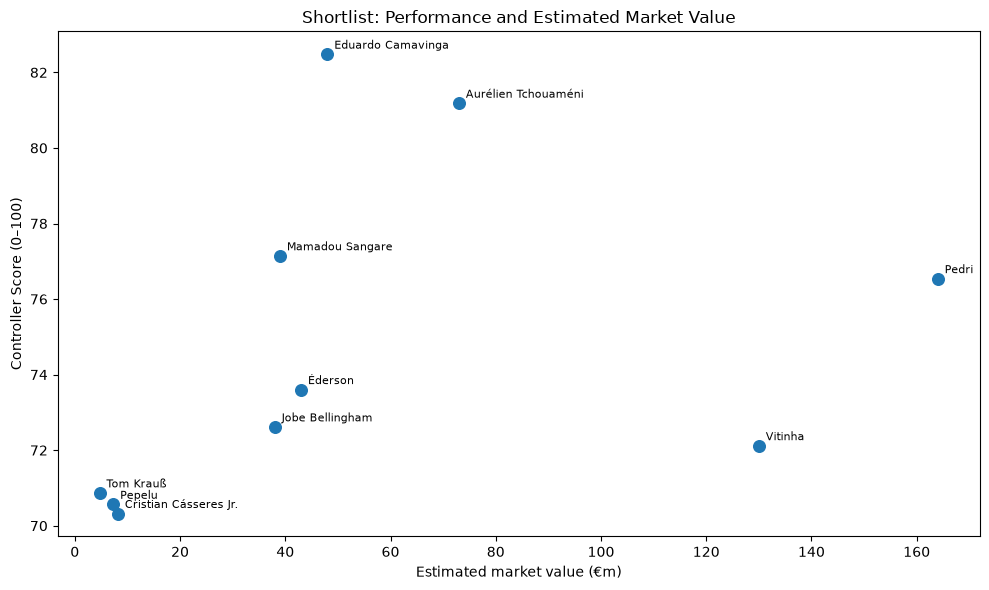

In [8]:
plot_df = shortlist.dropna(subset=["market_value_m", "controller_score"])
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot_df["market_value_m"], plot_df["controller_score"], s=70)
for _, r in plot_df.iterrows():
    ax.annotate(r["player"], (r["market_value_m"], r["controller_score"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Estimated market value (€m)", ylabel="Controller Score (0–100)",
       title="Shortlist: Performance and Estimated Market Value")
fig.tight_layout()
plt.savefig(
    PROJECT_ROOT / "assets" / "performance_vs_value.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Findings: Performance vs Estimated Market Value

The scatter plot compares the ten shortlisted midfielders using their Defensive Controller Scores and estimated market values.

The objective is to identify players who combine strong role-specific performance with potentially more accessible valuations.

**Key findings:**

- **Eduardo Camavinga (€48m, 82.5)** achieves the highest Controller Score, outperforming all other shortlisted players despite having a lower estimated market value than several elite candidates.

- **Aurélien Tchouaméni (€73m, 81.2)** ranks second and offers another strong performance profile, although his estimated valuation and preliminary feasibility classification suggest significant recruitment challenges.

- **Mamadou Sangare (€39m, 77.1)** delivers the third-highest Controller Score at a lower estimated valuation than Camavinga, Tchouaméni, Pedri and Vitinha.

- **Pedri (€164m, 76.5)** and **Vitinha (€130m, 72.1)** occupy the high-valuation end of the chart. Their estimated market values are substantially higher than those of several players with comparable or stronger Controller Scores.

- **Tom Krauß (€4.7m, 70.9), Pepelu (€7.3m, 70.6) and Cristian Cásseres Jr. (€8.2m, 70.3)** form a distinct lower-valuation group. All three remain within the top 10% of the recruitment pool by Controller Score.

**Recruitment interpretation:**

The shortlist reveals two broad recruitment approaches:

1. **Elite-performance targets:** Players such as Camavinga and Tchouaméni offer exceptional modelled performance but may face substantial acquisition barriers.
2. **Lower-valuation alternatives:** Krauß, Pepelu and Cásseres Jr. offer competitive role-specific scores at much lower estimated market values.

These lower-valuation candidates deserve further scouting attention, although their overall Controller Scores remain below those of the leading players.

**Conclusion:** Estimated market value introduces an important recruitment constraint that changes how the performance shortlist should be interpreted.

The chart highlights potentially interesting performance-versus-valuation trade-offs, but estimated market values are not transfer fees. Contract situations, club willingness to sell, wages and player preferences must be investigated before assessing actual affordability or transfer feasibility.



## 5. Final Recruitment Comparison

### 5.1 Compare Priority Candidates

The performance rankings, tactical profiles and estimated market values identify five players for closer recruitment consideration:

- Eduardo Camavinga - elite performance benchmark
- Aurélien Tchouaméni - possession-oriented controller
- Mamadou Sangare - ball-recovery specialist
- Éderson - balanced midfield option
- Tom Krauß - lower-valuation alternative

The objective is to compare their overall Controller Scores, tactical strengths, estimated market values and preliminary recruitment-feasibility classifications.

These five players represent different recruitment approaches rather than a definitive list of attainable transfer targets.


In [5]:
priority_players = [
    "Eduardo Camavinga",
    "Aurélien Tchouaméni",
    "Mamadou Sangare",
    "Éderson",
    "Tom Krauß"
]

comparison_columns = [
    "player",
    "age",
    "season_teams",
    "controller_score",
    "market_value_m",
    "defensive_activity_score",
    "possession_control_score",
    "progression_score",
    "ball_recovery_score",
    "physical_duels_score",
    "feasibility_tier"
]

priority_comparison = (
    shortlist.loc[
        shortlist["player"].isin(priority_players),
        comparison_columns
    ]
    .sort_values("controller_score", ascending=False)
    .reset_index(drop=True)
)

display(priority_comparison.round(1))

,player,age,season_teams,controller_score,market_value_m,defensive_activity_score,possession_control_score,progression_score,ball_recovery_score,physical_duels_score,feasibility_tier
0,Eduardo Camavinga,23.6,Real Madrid,82.5,48.0,77.7,90.3,88.7,62.1,95.4,Very Difficult
1,Aurélien Tchouaméni,26.4,Real Madrid,81.2,73.0,82.9,93.7,72.4,62.9,89.7,Very Difficult
2,Mamadou Sangare,24.0,RC Lens,77.1,39.0,75.3,59.1,79.8,99.6,88.7,Very Difficult
3,Éderson,27.0,Atalanta,73.6,43.0,66.8,77.2,77.4,80.6,66.9,Difficult
4,Tom Krauß,25.0,1. FC Köln,70.9,4.7,89.2,56.9,34.9,94.8,86.9,Potential Opportunity



### Findings: Priority Recruitment Comparison

The five selected candidates demonstrate different strengths and recruitment trade-offs.

| Player | Controller Score | Estimated Value | Preliminary Feasibility |
|---|---:|---:|---|
| Eduardo Camavinga | 82.5 | €48m | Very Difficult |
| Aurélien Tchouaméni | 81.2 | €73m | Very Difficult |
| Mamadou Sangare | 77.1 | €39m | Very Difficult |
| Éderson | 73.6 | €43m | Difficult |
| Tom Krauß | 70.9 | €4.7m | Potential Opportunity |

**Key findings:**

- Camavinga offers the highest overall performance score and an excellent combination of possession control, progression and physical effectiveness.
- Tchouaméni provides particularly strong possession control and defensive activity, making him an attractive tactical benchmark.
- Sangare is the strongest ball-recovery specialist among these five, although his possession-control score is comparatively lower.
- Éderson offers a relatively balanced performance profile without the same extreme strengths or weaknesses.
- Krauß provides strong defensive activity and ball recovery at a considerably lower estimated valuation, but his progression score is notably weaker.

**Recruitment interpretation:**

Camavinga and Tchouaméni represent elite performance benchmarks, while Sangare and Éderson offer alternative tactical profiles.

Krauß emerges as a lower-valuation candidate worthy of further investigation, particularly if Manchester United prioritises defensive activity and ball recovery.

However, his lower progression and possession-control scores suggest that he may not fully replicate the responsibilities of an elite possession-oriented Defensive Controller.

The feasibility classifications are preliminary and require independent verification of contracts, transfer availability, wages and club circumstances.



### 5.2 Final Recruitment Recommendations

The final recommendations combine the performance-based Controller Score, tactical dimension scores, estimated market values and preliminary recruitment-feasibility assessments.

The objective is not simply to identify the highest-scoring midfielder, but to distinguish elite tactical benchmarks from candidates who warrant further recruitment investigation.

#### Priority 1 — Éderson: Balanced Midfield Option

- **Controller Score:** 73.6
- **Estimated Market Value:** €43m
- **Age:** 27.0
- **Preliminary Feasibility:** Difficult

Éderson demonstrates a relatively balanced profile across possession control (77.2), progression (77.4) and ball recovery (80.6).

His profile makes him an interesting candidate for a role requiring contributions across multiple phases of play rather than exceptional performance in one particular dimension.

**Recommendation:** Prioritise for detailed tactical scouting as a potential all-round midfield option.

**Main limitation:** His defensive activity (66.8) and physical/duel score (66.9) are lower than those of several other shortlisted candidates. His estimated valuation and acquisition feasibility also require further investigation.

#### Priority 2 — Tom Krauß: Lower-Valuation Opportunity

- **Controller Score:** 70.9
- **Estimated Market Value:** €4.7m
- **Age:** 25.0
- **Preliminary Feasibility:** Potential Opportunity

Krauß combines strong defensive activity (89.2), ball recovery (94.8) and physical/duel performance (86.9) with the lowest estimated market value among the five priority candidates.

He represents an interesting option for a recruitment strategy emphasising defensive intensity and potential value.

**Recommendation:** Prioritise for further scouting as a lower-valuation, defensively oriented midfield option.

**Main limitation:** His possession control (56.9) and particularly progression (34.9) suggest that he may not offer the complete ball-playing profile required of an elite Defensive Controller.

#### Priority 3 — Mamadou Sangare: Ball-Recovery Specialist

- **Controller Score:** 77.1
- **Estimated Market Value:** €39m
- **Age:** 24.0
- **Preliminary Feasibility:** Very Difficult

Sangare ranks third overall and demonstrates exceptional ball recovery (99.6), strong physical/duel performance (88.7) and progression (79.8).

At 24, he also fits the project's preference for a player who may have further development potential.

**Recommendation:** Retain as a high-priority tactical scouting target, particularly if Manchester United prioritises ball recovery and defensive disruption.

**Main limitation:** His possession-control score (59.1) is substantially below those of Camavinga and Tchouaméni. His preliminary feasibility classification also indicates significant recruitment challenges.

#### Elite Benchmarks — Camavinga and Tchouaméni

Eduardo Camavinga (82.5) and Aurélien Tchouaméni (81.2) lead the overall performance model.

Both demonstrate strong possession-control and physical/duel profiles, making them valuable reference points for the desired Defensive Controller role.

However, both are provisionally classified as Very Difficult recruitment targets.

**Recommendation:** Use these players as elite performance benchmarks when evaluating alternative candidates, rather than assuming they represent realistic transfer opportunities.

### Overall Recommendation

The analysis supports a differentiated recruitment strategy:

1. **Éderson:** Investigate as a balanced midfield option.
2. **Tom Krauß:** Investigate as a lower-valuation defensive specialist.
3. **Mamadou Sangare:** Retain as a high-performing ball-recovery specialist, subject to feasibility.

Camavinga and Tchouaméni provide elite benchmarks against which these alternatives can be assessed.

These recommendations are preliminary. Final transfer decisions require video scouting, tactical-context analysis, injury and availability assessments, contract information, wage expectations and verified acquisition costs.

The model provides an evidence-based starting point for recruitment decisions, not a substitute for professional scouting.



## 6. Project Limitations and Final Conclusions

### 6.1 Limitations of the Analysis

Although the Defensive Controller recruitment model provides a structured, data-driven approach to evaluating midfielders, several limitations must be acknowledged.

**1. Data coverage**

The analysis uses 2025/26 performance statistics from Europe's Big Five leagues.

Player metadata could not be retrieved for every eligible player due to collection restrictions. Consequently, some potentially suitable midfielders may be absent from the recruitment pool.

**2. Tactical context**

Performance statistics are influenced by team playing style, possession share, league strength and individual tactical responsibilities.

A midfielder playing in a high-possession team may accumulate more passes than an equally capable player in a lower-possession team.

The model does not explicitly adjust for these contextual differences.

**3. Feature availability**

The dataset does not provide every metric relevant to the Defensive Controller role.

For example, completed final-third passes and long balls are used as progression indicators, but they do not directly measure progressive passes, progressive carries or line-breaking actions.

Similarly, per-90 defensive statistics do not fully capture positioning, anticipation or off-ball defensive intelligence.

**4. Subjective feature weights**

The Controller Score uses five weighted dimensions:

| Dimension | Weight |
|---|---:|
| Defensive Activity | 30% |
| Possession Control | 25% |
| Progression | 20% |
| Ball Recovery | 15% |
| Physical/Duels | 10% |

These weights represent a tactical interpretation of Manchester United's recruitment requirements rather than coefficients learned from historical transfer success.

Sensitivity analysis was conducted in Notebook 02 to examine how rankings respond to alternative weighting assumptions.

**5. Market valuation**

Estimated market values are not equivalent to actual transfer fees.

The market-value regression also has limited explanatory power (R² ≈ 0.137), indicating that valuation explains only a small proportion of the variation in Controller Scores within the analysed recruitment pool.

Positive value residuals therefore indicate performance above the model's expected score at a given valuation, not proven market undervaluation.

**6. Transfer feasibility**

The feasibility tiers are preliminary assessments rather than verified measures of transfer availability.

The analysis does not incorporate confirmed asking prices, contract clauses, wage demands, player preferences or negotiations between clubs.

**7. External validation**

The Controller Score has not been validated against future player performance or successful transfers.

The rankings should therefore be interpreted as an exploratory recruitment decision-support tool rather than a predictive measure of transfer success.

---

### 6.2 Executive Summary

This project investigated how Manchester United could use football performance data to identify midfielders suited to a Defensive Controller role.

The analysis focused on defensive activity, possession control, ball progression, ball recovery and physical effectiveness.

**Recruitment pipeline:**

- Analysed 2025/26 performance data from Europe's Big Five leagues.
- Identified 349 midfielders with detailed positional metadata.
- Retained 248 midfielders meeting the minimum 1,500-minute requirement.
- Applied recruitment criteria to establish a pool of 95 candidates aged 28 or younger, excluding players with Premier League involvement.
- Selected the top 10% of the recruitment pool using the weighted Defensive Controller Score, producing a shortlist of ten players.

**Principal findings:**

Eduardo Camavinga (82.5) and Aurélien Tchouaméni (81.2) achieved the highest overall Controller Scores and provide elite performance benchmarks.

Mamadou Sangare (77.1) demonstrated a particularly strong ball-recovery profile, while Éderson (73.6) offered relatively balanced contributions across the five dimensions.

Tom Krauß (70.9) emerged as an interesting lower-valuation alternative, combining strong defensive activity and ball recovery with an estimated market value of €4.7 million.

However, Krauß's weaker progression and possession-control scores illustrate the trade-offs involved in selecting a more affordable candidate.

### 6.3 Final Recommendation

The analysis recommends three players for further scouting consideration:

1. **Éderson:** A balanced midfield option who contributes across possession, progression and recovery.
2. **Tom Krauß:** A lower-valuation defensive specialist whose ball-winning attributes merit further investigation.
3. **Mamadou Sangare:** A high-performing ball-recovery specialist whose tactical fit and acquisition feasibility require further assessment.

Camavinga and Tchouaméni should remain elite performance benchmarks.

These recommendations are intended to guide further scouting rather than represent definitive transfer decisions.

### 6.4 Project Outcome

The project demonstrates how a football recruitment problem can be translated into a reproducible analytical workflow.

It combines data collection, data quality assessment, feature engineering, interpretable weighted scoring, sensitivity analysis, market-value comparisons and recruitment-oriented visualisation.

The resulting framework supports transparent comparison of midfielders and provides a foundation for more advanced recruitment analytics incorporating tactical context, video scouting and validated transfer-feasibility information.
